In [1]:
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

load_dotenv()

engine = create_engine(
    "postgresql+psycopg2://{user}:{pw}@{host}:{port}/{db}".format(
        user=os.environ["DB_USER"], pw=os.environ["DB_PASSWORD"],
        host=os.environ["DB_HOST"], port=os.environ.get("DB_PORT", "5432"),
        db=os.environ["DB_NAME"],
    )
)

df = pd.read_sql("""
    SELECT p.requires_cold_chain,
           COUNT(a.alert_id) AS total_alerts,
           COUNT(DISTINCT b.product_ndc) AS total_products,
           ROUND(COUNT(a.alert_id)::decimal / NULLIF(COUNT(DISTINCT b.product_ndc), 0), 2) AS alerts_per_product
    FROM project.products p
    JOIN project.batches b ON b.product_ndc = p.product_ndc
    JOIN project.alerts a ON a.batch_id = b.batch_id
    GROUP BY p.requires_cold_chain
""", engine)

print(df)

   requires_cold_chain  total_alerts  total_products  alerts_per_product
0                False           265             189                1.40
1                 True            35              29                1.21


In [2]:
df = pd.read_sql("""
    SELECT 
        p.product_ndc,
        p.requires_cold_chain,
        COUNT(a.alert_id) AS alert_count
    FROM project.products p
    JOIN project.batches b ON b.product_ndc = p.product_ndc
    LEFT JOIN project.alerts a ON a.batch_id = b.batch_id
    GROUP BY p.product_ndc, p.requires_cold_chain
""", engine)

print(df['requires_cold_chain'].value_counts())
print(df.groupby('requires_cold_chain')['alert_count'].describe())

# t-test
cold = df[df['requires_cold_chain'] == True]['alert_count']
warm = df[df['requires_cold_chain'] == False]['alert_count']

t_stat, p_value = stats.ttest_ind(cold, warm)
print(f"\nt-statistic : {t_stat:.4f}")
print(f"p-value     : {p_value:.4f}")
print(f"Conclusion  : {'Significant difference ' if p_value < 0.05 else 'No significant difference '}")

requires_cold_chain
False    430
True      70
Name: count, dtype: int64
                     count      mean       std  min  25%  50%  75%  max
requires_cold_chain                                                    
False                430.0  0.616279  0.813187  0.0  0.0  0.0  1.0  4.0
True                  70.0  0.500000  0.653863  0.0  0.0  0.0  1.0  2.0

t-statistic : -1.1377
p-value     : 0.2558
Conclusion  : No significant difference 


Total shipments: 14771
Locations      : 30

                        mean_hours  std_hours  shipments
location                                                
Warehouse 6              12.669216   6.625993        523
Cold Storage 12          12.473577   6.555832        492
Distribution Center 18   12.434211   6.475317        456
Distribution Center 15   12.392308   6.804732        520
Warehouse 26             12.298137   6.803262        483
Distribution Center 23   12.249489   6.683961        489
Warehouse 20             12.201161   6.522038        517
Distribution Center 19   12.193059   6.600695        461
Distribution Center 21   12.176113   6.768211        494
Distribution Center 13   12.126582   6.772099        474
Warehouse 14             12.059574   6.502801        470
Distribution Center 16   12.018711   6.599689        481
Distribution Center 30   12.001931   6.656681        518
Distribution Center 4    11.970530   6.678582        509
Warehouse 9              11.941176   6.67874

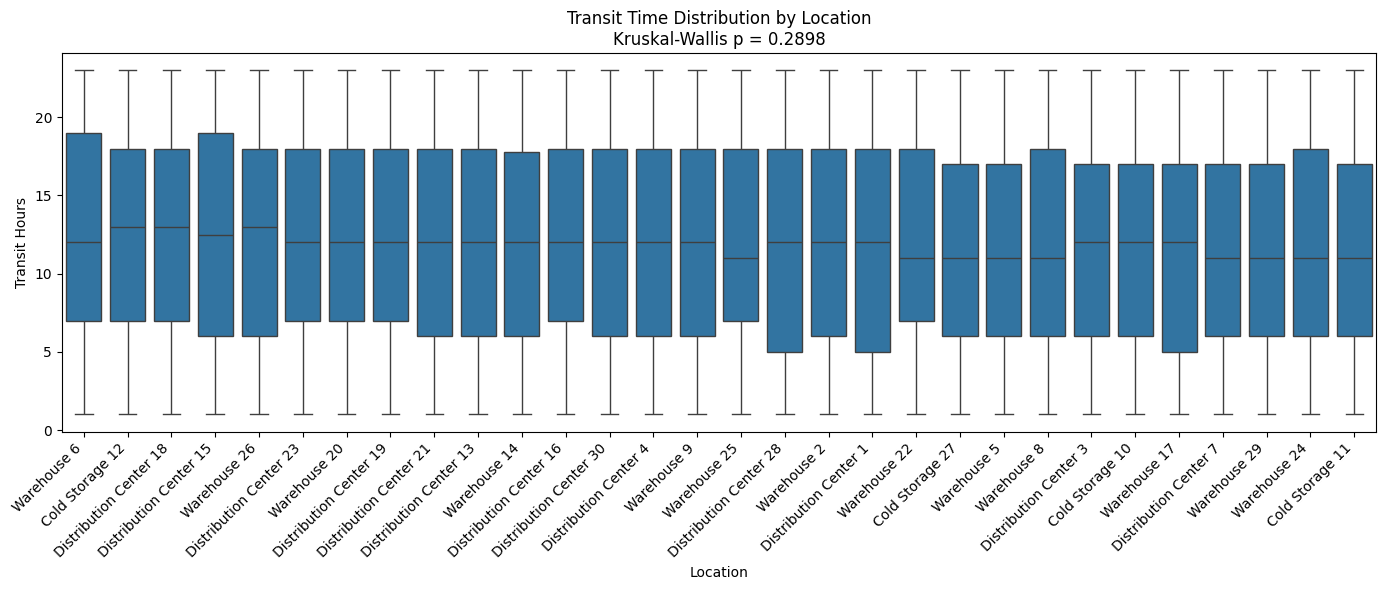

In [3]:



df_2 = pd.read_sql("""
    SELECT 
        il.name AS location,
        il.type AS location_type,
        EXTRACT(HOURS FROM (ml.arrival_time - ml.departure_time)) AS transit_hours
    FROM project.movement_logs ml
    JOIN project.inventory_locations il ON il.location_id = ml.from_location_id
    WHERE ml.arrival_time IS NOT NULL
    AND EXTRACT(HOURS FROM (ml.arrival_time - ml.departure_time)) > 0
""", engine)

print(f"Total shipments: {len(df_2)}")
print(f"Locations      : {df_2['location'].nunique()}")
print()

#  Descriptive stats per location 
desc = df_2.groupby('location')['transit_hours'].agg(['mean', 'std', 'count'])
desc.columns = ['mean_hours', 'std_hours', 'shipments']
desc = desc.sort_values('mean_hours', ascending=False)
print(desc.to_string())
print()

#  Kruskal-Wallis test since transit times are not normally distributed

groups = [group['transit_hours'].values for _, group in df_2.groupby('location')]
stat, p_value = stats.kruskal(*groups)

print(f"Kruskal-Wallis H-statistic : {stat:.4f}")
print(f"p-value                    : {p_value:.4f}")
print(f"Conclusion : {'Significant difference between locations ✅' if p_value < 0.05 else 'No significant difference ❌'}")
print()

#  Post-hoc: which locations differ? (Mann-Whitney pairwise) 
if p_value < 0.05:
    locations = df_2['location'].unique()
    print("Pairwise Mann-Whitney U tests (p < 0.05 = significantly different):")
    print(f"{'Location A':<30} {'Location B':<30} {'p-value':<10}")
    print("-" * 70)
    for i in range(len(locations)):
        for j in range(i + 1, len(locations)):
            a = df_2[df_2['location'] == locations[i]]['transit_hours']
            b = df_2[df_2['location'] == locations[j]]['transit_hours']
            _, p = stats.mannwhitneyu(a, b, alternative='two-sided')
            if p < 0.05:
                print(f"{locations[i]:<30} {locations[j]:<30} {p:.4f} ✅")

#  Visualisation
plt.figure(figsize=(14, 6))
sns.boxplot(data=df_2, x='location', y='transit_hours', order=desc.index)
plt.xticks(rotation=45, ha='right')
plt.title('Transit Time Distribution by Location\n'
          f'Kruskal-Wallis p = {p_value:.4f}')
plt.xlabel('Location')
plt.ylabel('Transit Hours')
plt.tight_layout()
plt.savefig('transit_times_by_location.png', dpi=150)
plt.show()
